In [1]:
import requests
import pandas as pd
import numpy as np
import time
from datetime import datetime, timezone

In [2]:
GAMMA_API = "https://gamma-api.polymarket.com"
DATA_API = "https://data-api.polymarket.com"

REQUEST_TIMEOUT = 30

In [3]:
all_markets = []

for offset in range(0, 1000, 100):
    response = requests.get(
        f"{GAMMA_API}/markets",
        params={
            "limit": 100,
            "offset": offset
        },
        timeout=REQUEST_TIMEOUT
    )

    response.raise_for_status()

    batch = response.json()
    all_markets.extend(batch)

    print(f"Offset {offset}: {len(batch)} markets")

    if len(batch) < 100:
        break

    time.sleep(0.2)

markets_df = pd.DataFrame(all_markets)

print("\nTotal markets:", len(markets_df))

Offset 0: 100 markets
Offset 100: 100 markets
Offset 200: 100 markets
Offset 300: 100 markets
Offset 400: 100 markets
Offset 500: 100 markets
Offset 600: 100 markets
Offset 700: 100 markets
Offset 800: 100 markets
Offset 900: 100 markets

Total markets: 1000


In [4]:
selected_ids = [
    665374,
    567621,
    663583,
    560317,
    616913,
    637002,
    608553,
    562803,
    628944,
    629040
]

selected_markets = markets_df[
    markets_df["id"].isin(selected_ids)
].copy()

selected_markets[
    ["id", "question", "conditionId", "volume", "liquidity"]
].sort_values("volume", ascending=False)

,id,question,conditionId,volume,liquidity


In [5]:
selected_ids = [
    "665374",
    "567621",
    "663583",
    "560317",
    "616913",
    "637002",
    "608553",
    "562803",
    "628944",
    "629040"
]

selected_markets = markets_df[
    markets_df["id"].astype(str).isin(selected_ids)
].copy()

print("Selected markets:", len(selected_markets))

selected_markets[
    ["id", "question", "conditionId", "volume", "liquidity"]
].sort_values(
    "volume",
    ascending=False
)

Selected markets: 10


,id,question,conditionId,volume,liquidity
535,665374,Will the U.S. invade Iran before 2027?,0x5db999fad322cea2914535aae5517060c3f80ad6d8c0...,67642128.67032102,752989.3955
237,616913,Will 11 Fed rate cuts happen in 2026?,0x1adf074e048fa613f4ddbc0766088748a48d120a3a71...,5268833.838101001,534829.15183
150,562803,Will the Republican Party control the House af...,0x4e4f77e7dbf4cab666e9a1943674d7ae66348e862df0...,5048515.771806999,570813.7875
441,637002,Will Donald Trump win the Nobel Peace Prize in...,0x962e5b226a77266ab429029ee04665e8fcfeb10b91af...,4987165.101333001,396192.97295
159,567621,Will China invade Taiwan by end of 2026?,0xd9fb1184af0064e5e34b129f5b79afa5a17b7e32f295...,42582538.289005846,571154.13266
482,663583,Will the Iranian regime fall before 2027?,0xbb4d51e6364066d92eb6f9b8413dd7193de709667360...,26213351.788787015,573303.7366
52,560317,Putin out as President of Russia by December 3...,0x6bd56627aa21311850825edb27e53434a0e17a4f782b...,21919453.485232998,887755.8519
253,628944,Will Betty Yee win the California Governor Ele...,0x43cf1b93d1b5420b158346f0e6e2993432014c4c09a2...,1748030.82878201,351505.8184
269,629040,Will Nithya Raman win the 2026 Los Angeles may...,0x694595d0a008f10e4701285d071e4b08407495f6f8a6...,1744042.1882640002,173873.16611
215,608553,Will Khvicha Kvaratskhelia win the 2026 Ballon...,0x9f50939c394897a984d04522b61cf62da5aaa7fc50a2...,1731764.0183749995,109669.65887


In [6]:
test_market = selected_markets.iloc[0]

print("Market:", test_market["question"])
print("Condition ID:", test_market["conditionId"])

Market: Putin out as President of Russia by December 31, 2026?
Condition ID: 0x6bd56627aa21311850825edb27e53434a0e17a4f782be0086bc07f71eee00d0d


In [7]:
def get_market_trades(condition_id, max_trades=10000):
    all_trades = []

    for offset in range(0, max_trades, 100):
        response = requests.get(
            f"{DATA_API}/trades",
            params={
                "market": condition_id,
                "limit": 100,
                "offset": offset,
                "takerOnly": False
            },
            timeout=REQUEST_TIMEOUT
        )

        response.raise_for_status()

        batch = response.json()

        if not batch:
            break

        all_trades.extend(batch)

        print(
            f"Offset {offset}: "
            f"{len(batch)} trades"
        )

        if len(batch) < 100:
            break

        time.sleep(0.2)

    return pd.DataFrame(all_trades)

In [9]:
test_trades_df = get_market_trades(
    test_market["conditionId"],
    max_trades=10000
)

print("\nTotal trades:", len(test_trades_df))

Offset 0: 100 trades
Offset 100: 100 trades
Offset 200: 100 trades
Offset 300: 100 trades
Offset 400: 100 trades
Offset 500: 100 trades
Offset 600: 100 trades
Offset 700: 100 trades
Offset 800: 100 trades
Offset 900: 100 trades
Offset 1000: 100 trades
Offset 1100: 100 trades
Offset 1200: 100 trades
Offset 1300: 100 trades
Offset 1400: 100 trades
Offset 1500: 100 trades
Offset 1600: 100 trades
Offset 1700: 100 trades
Offset 1800: 100 trades
Offset 1900: 100 trades
Offset 2000: 100 trades
Offset 2100: 100 trades
Offset 2200: 100 trades
Offset 2300: 100 trades
Offset 2400: 100 trades
Offset 2500: 100 trades
Offset 2600: 100 trades
Offset 2700: 100 trades
Offset 2800: 100 trades
Offset 2900: 100 trades
Offset 3000: 100 trades
Offset 3100: 100 trades
Offset 3200: 100 trades
Offset 3300: 100 trades
Offset 3400: 100 trades
Offset 3500: 100 trades
Offset 3600: 100 trades
Offset 3700: 100 trades
Offset 3800: 100 trades
Offset 3900: 100 trades
Offset 4000: 100 trades
Offset 4100: 100 trades
Offs

In [10]:
def build_temporal_edges(
    trades_df,
    window_seconds=5 * 60
):
    trades = trades_df.copy()

    trades = trades.sort_values(
        ["datetime", "proxyWallet"]
    ).reset_index(drop=True)

    edges = []

    for i in range(len(trades)):

        trade_a = trades.iloc[i]

        for j in range(i + 1, len(trades)):

            trade_b = trades.iloc[j]

            time_diff = (
                trade_b["datetime"] -
                trade_a["datetime"]
            ).total_seconds()

            if time_diff > window_seconds:
                break

            # Don't connect a wallet to itself
            if trade_a["proxyWallet"] == trade_b["proxyWallet"]:
                continue

            price_diff = abs(
                float(trade_a["price"]) -
                float(trade_b["price"])
            )

            size_a = float(trade_a["size"])
            size_b = float(trade_b["size"])

            if max(size_a, size_b) > 0:
                size_ratio = (
                    min(size_a, size_b) /
                    max(size_a, size_b)
                )
            else:
                size_ratio = 0.0

            edges.append({
                "source": trade_a["proxyWallet"],
                "target": trade_b["proxyWallet"],

                "timestamp": trade_b["datetime"],

                "time_diff": time_diff,

                "same_side": int(
                    trade_a["side"] ==
                    trade_b["side"]
                ),

                "same_outcome": int(
                    trade_a["outcome"] ==
                    trade_b["outcome"]
                ),

                "price_diff": price_diff,

                "size_ratio": size_ratio,

                "source_side": trade_a["side"],
                "target_side": trade_b["side"],

                "source_outcome": trade_a["outcome"],
                "target_outcome": trade_b["outcome"],

                "source_size": size_a,
                "target_size": size_b,

                "source_price": float(trade_a["price"]),
                "target_price": float(trade_b["price"])
            })

    return pd.DataFrame(edges)

In [11]:
test_trades_df["datetime"] = pd.to_datetime(
    test_trades_df["timestamp"],
    unit="s",
    utc=True
)

In [12]:
temporal_edges = build_temporal_edges(
    test_trades_df,
    window_seconds=5 * 60
)

print("Temporal edges:", len(temporal_edges))

Temporal edges: 103779


In [13]:
print(
    "Unique source wallets:",
    temporal_edges["source"].nunique()
)

print(
    "Unique target wallets:",
    temporal_edges["target"].nunique()
)

print(
    "Unique wallet pairs:",
    temporal_edges[
        ["source", "target"]
    ].drop_duplicates().shape[0]
)

Unique source wallets: 2051
Unique target wallets: 1780
Unique wallet pairs: 32108


In [14]:
temporal_edges[
    [
        "time_diff",
        "same_side",
        "same_outcome",
        "price_diff",
        "size_ratio"
    ]
].describe()

,time_diff,same_side,same_outcome,price_diff,size_ratio
count,103779.000000,103779.000000,103779.000000,103779.000000,1.037790e+05
mean,38.432592,0.544532,0.543617,0.401380,2.930714e-01
std,75.024904,0.498015,0.498096,0.434054,3.389654e-01
min,0.000000,0.000000,0.000000,0.000000,1.787150e-07
25%,0.000000,0.000000,0.000000,0.000000,2.076500e-02
50%,2.000000,1.000000,1.000000,0.010000,1.222219e-01
75%,28.000000,1.000000,1.000000,0.870000,5.000000e-01
max,300.000000,1.000000,1.000000,0.940000,1.000000e+00


In [15]:
print(
    temporal_edges["same_outcome"]
    .value_counts(normalize=True)
)

print(
    temporal_edges["same_side"]
    .value_counts(normalize=True)
)

same_outcome
1    0.543617
0    0.456383
Name: proportion, dtype: float64
same_side
1    0.544532
0    0.455468
Name: proportion, dtype: float64


In [16]:
print(
    temporal_edges.groupby("same_outcome")["price_diff"].describe()
)
print(
    temporal_edges.groupby("same_side")["price_diff"].describe()
)

                count      mean       std   min   25%   50%   75%   max
same_outcome                                                           
0             47363.0  0.874663  0.026976  0.82  0.85  0.88  0.90  0.94
1             56416.0  0.004044  0.005543  0.00  0.00  0.00  0.01  0.03
             count      mean       std  min   25%   50%   75%   max
same_side                                                          
0          47268.0  0.531856  0.428087  0.0  0.01  0.85  0.89  0.94
1          56511.0  0.292244  0.408117  0.0  0.00  0.01  0.85  0.94


In [17]:
print("Unique wallets:", test_trades_df["proxyWallet"].nunique())

print(
    "Unique wallet pairs:",
    temporal_edges[["source", "target"]].drop_duplicates().shape[0]
)

print(
    "Edges per wallet pair:"
)
print(
    temporal_edges.groupby(
        ["source", "target"]
    ).size().describe()
)

Unique wallets: 2356
Unique wallet pairs: 32108
Edges per wallet pair:
count    32108.000000
mean         3.232185
std         14.509877
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max       1058.000000
dtype: float64


In [18]:
temporal_edges["same_behavior"] = (
    temporal_edges["same_side"] &
    temporal_edges["same_outcome"]
).astype(int)

In [19]:
print(
    temporal_edges["same_behavior"]
    .value_counts(normalize=True)
)

same_behavior
0    0.63695
1    0.36305
Name: proportion, dtype: float64


In [20]:
# Unique wallets involved in temporal edges
wallets_in_graph = set(
    temporal_edges["source"]
).union(
    temporal_edges["target"]
)

print("Wallets in graph:", len(wallets_in_graph))

# Unique directed wallet pairs
unique_pairs = temporal_edges[
    ["source", "target"]
].drop_duplicates()

print("Unique wallet pairs:", len(unique_pairs))

# Number of temporal interactions per wallet pair
pair_counts = (
    temporal_edges
    .groupby(["source", "target"])
    .size()
)

print("\nInteractions per wallet pair:")
print(pair_counts.describe())

Wallets in graph: 2356
Unique wallet pairs: 32108

Interactions per wallet pair:
count    32108.000000
mean         3.232185
std         14.509877
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max       1058.000000
dtype: float64


In [21]:
# Number of distinct neighbors per wallet
degree = pd.concat([
    temporal_edges[["source", "target"]]
        .rename(columns={"source": "wallet", "target": "neighbor"}),

    temporal_edges[["target", "source"]]
        .rename(columns={"target": "wallet", "source": "neighbor"})
]).drop_duplicates()

degree_counts = degree.groupby("wallet").size()

print("\nWallet degree:")
print(degree_counts.describe())


Wallet degree:
count    2356.000000
mean       23.855688
std        55.960674
min         1.000000
25%         2.000000
50%         4.000000
75%        15.000000
max      1017.000000
dtype: float64


In [22]:
top_pairs = (
    temporal_edges
    .groupby(["source", "target"])
    .size()
    .sort_values(ascending=False)
    .head(20)
)

top_pairs

source                                      target                                    
0xb886580698ede4b18de3e446b2d8da8bcedd81b3  0xe23b29408015a53249709a4e8331f9358c89f147    1058
0x919a9a3f3fb9265560703cf6fe3b38567f3b87b9  0xab19716584931d81cd9e7763402673a64baa4876     760
0xab19716584931d81cd9e7763402673a64baa4876  0x919a9a3f3fb9265560703cf6fe3b38567f3b87b9     725
0xb886580698ede4b18de3e446b2d8da8bcedd81b3  0xeed8c2be411025120fb511ea2332dd0a1f6135f0     722
0x919a9a3f3fb9265560703cf6fe3b38567f3b87b9  0xb886580698ede4b18de3e446b2d8da8bcedd81b3     709
0xb886580698ede4b18de3e446b2d8da8bcedd81b3  0x919a9a3f3fb9265560703cf6fe3b38567f3b87b9     636
0xab19716584931d81cd9e7763402673a64baa4876  0xb886580698ede4b18de3e446b2d8da8bcedd81b3     602
0xe23b29408015a53249709a4e8331f9358c89f147  0xeed8c2be411025120fb511ea2332dd0a1f6135f0     462
0xb886580698ede4b18de3e446b2d8da8bcedd81b3  0xab19716584931d81cd9e7763402673a64baa4876     455
0xe23b29408015a53249709a4e8331f9358c89f147  0xb66582886125

In [23]:
top_wallets = (
    test_trades_df["proxyWallet"]
    .value_counts()
    .head(20)
)

top_wallets

proxyWallet
0xb886580698ede4b18de3e446b2d8da8bcedd81b3    959
0xab19716584931d81cd9e7763402673a64baa4876    532
0xa58d4f278d7953cd38eeb929f7e242bfc7c0b9b8    323
0x8afa03dd6974e44d00c4d14dcccb00c0ddf6adb6    201
0xd7eee5e918dc59fa32386a4ad8a89655946e9597    167
0xe23b29408015a53249709a4e8331f9358c89f147    161
0xa6d9b55a6a3a54a9d50ca94c64f00af69c50fd2f    105
0x9d84ce0306f8551e02efef1680475fc0f1dc1344    105
0x9c2617462567859fcf5764e03b9a687ebca274bc    103
0xc02147dee42356b7a4edbb1c35ac4ffa95f61fa8     91
0xfb4defb359e998ade4694a5326b377ed1780ef35     90
0x10a7268e8318af0d229b5fee65ecdc52a75e8652     87
0xf1ef8705e9f63c790c6fffd6329aea7011718cd6     83
0xeed8c2be411025120fb511ea2332dd0a1f6135f0     70
0x919a9a3f3fb9265560703cf6fe3b38567f3b87b9     68
0x21d0c129deb8a7f7e1569045200d20e23862ce91     60
0x3876a4840f46a1329179a34442d27db8642e4802     59
0xcc2982e3fbbcaf9af9fa373fa3ae392fd9457774     59
0xa61ef8773ec2e821962306ca87d4b57e39ff0abd     58
0xc87ae1463755dfd6412843f6275cccf2ca09

In [24]:
wallet_features = (
    test_trades_df
    .groupby("proxyWallet")
    .agg(
        trade_count=("proxyWallet", "size"),
        buy_count=("side", lambda x: (x == "BUY").sum()),
        sell_count=("side", lambda x: (x == "SELL").sum()),
        avg_trade_size=("size", "mean"),
        median_trade_size=("size", "median"),
        avg_price=("price", "mean"),
        price_std=("price", "std"),
        unique_outcomes=("outcome", "nunique"),
        first_trade=("datetime", "min"),
        last_trade=("datetime", "max")
    )
    .reset_index()
)

In [25]:
wallet_features["buy_ratio"] = (
    wallet_features["buy_count"] /
    wallet_features["trade_count"]
)

wallet_features["sell_ratio"] = (
    wallet_features["sell_count"] /
    wallet_features["trade_count"]
)

wallet_features["active_duration_hours"] = (
    (
        wallet_features["last_trade"] -
        wallet_features["first_trade"]
    ).dt.total_seconds() / 3600
)

wallet_features["trade_frequency"] = (
    wallet_features["trade_count"] /
    wallet_features["active_duration_hours"].clip(lower=1/60)
)

In [26]:
wallet_features.head()

,proxyWallet,trade_count,buy_count,sell_count,avg_trade_size,median_trade_size,avg_price,price_std,unique_outcomes,first_trade,last_trade,buy_ratio,sell_ratio,active_duration_hours,trade_frequency
0,0x00039cdf685d036595ed8f079a897de78f75e331,1,1,0,222.222221,222.222221,0.090,NaN,1,2026-07-20 15:36:18+00:00,2026-07-20 15:36:18+00:00,1.0,0.0,0.000000,60.000000
1,0x0072e290392e1165247c8c2ade58f043fe8a191e,1,0,1,26.000000,26.000000,0.910,NaN,1,2026-07-21 00:36:06+00:00,2026-07-21 00:36:06+00:00,0.0,1.0,0.000000,60.000000
2,0x0086646c84c241f443a9d51ee594e9d17d3677cb,2,1,1,4.420000,4.420000,0.935,0.007071,1,2026-09-01 16:28:49+00:00,2026-09-01 22:29:24+00:00,0.5,0.5,6.009722,0.332794
3,0x00a7af94d4e0316cce950e80652e1eaa6f00f430,1,1,0,125.000000,125.000000,0.080,NaN,1,2026-08-20 13:34:10+00:00,2026-08-20 13:34:10+00:00,1.0,0.0,0.000000,60.000000
4,0x00fea6a543b001c243afadeb90edfd416a11abeb,1,1,0,1.063828,1.063828,0.940,NaN,1,2026-09-03 16:29:40+00:00,2026-09-03 16:29:40+00:00,1.0,0.0,0.000000,60.000000


In [27]:
wallet_features.describe()

,trade_count,buy_count,sell_count,avg_trade_size,median_trade_size,avg_price,price_std,unique_outcomes,buy_ratio,sell_ratio,active_duration_hours,trade_frequency
count,2356.000000,2356.000000,2356.000000,2356.000000,2356.000000,2356.000000,1134.000000,2356.000000,2356.000000,2356.000000,2356.000000,2356.000000
mean,4.244482,2.382428,1.862054,712.552467,613.975471,0.710758,0.030376,1.026740,0.496805,0.503195,137.990081,34.267534
std,25.554813,15.811958,11.355857,4993.449093,4757.291006,0.365203,0.100214,0.161358,0.397740,0.397740,323.743317,32.314453
min,1.000000,0.000000,0.000000,0.010000,0.010000,0.034500,0.000000,1.000000,0.000000,0.000000,0.000000,0.001318
25%,1.000000,0.000000,0.000000,6.847500,6.657500,0.500000,0.005774,1.000000,0.000000,0.000000,0.000000,0.247187
50%,1.000000,1.000000,1.000000,22.580644,21.000000,0.915000,0.007071,1.000000,0.500000,0.500000,0.000000,60.000000
75%,2.000000,1.000000,1.000000,200.000000,150.557500,0.930000,0.007071,1.000000,1.000000,1.000000,8.617431,60.000000
max,959.000000,633.000000,342.000000,195592.660000,195592.660000,0.970000,0.636396,2.000000,1.000000,1.000000,1524.123056,199.673736


In [28]:
from sklearn.preprocessing import StandardScaler

In [29]:
wallets = sorted(
    set(temporal_edges["source"])
    .union(temporal_edges["target"])
)

wallet_to_id = {
    wallet: idx
    for idx, wallet in enumerate(wallets)
}

id_to_wallet = {
    idx: wallet
    for wallet, idx in wallet_to_id.items()
}

print("Number of nodes:", len(wallets))

Number of nodes: 2356


In [30]:
feature_columns = [
    "log_trade_count",
    "buy_ratio",
    "sell_ratio",
    "log_avg_trade_size",
    "log_median_trade_size",
    "avg_price",
    "price_std",
    "unique_outcomes",
    "log_active_duration"
]

In [31]:
node_features = wallet_features.copy()

node_features["price_std"] = (
    node_features["price_std"]
    .fillna(0)
)

node_features["log_trade_count"] = np.log1p(
    node_features["trade_count"]
)

node_features["log_avg_trade_size"] = np.log1p(
    node_features["avg_trade_size"]
)

node_features["log_median_trade_size"] = np.log1p(
    node_features["median_trade_size"]
)

node_features["log_active_duration"] = np.log1p(
    node_features["active_duration_hours"]
)

In [32]:
node_features_graph = (
    node_features[
        node_features["proxyWallet"].isin(wallets)
    ]
    .copy()
)

node_features_graph["node_id"] = (
    node_features_graph["proxyWallet"]
    .map(wallet_to_id)
)

node_features_graph = (
    node_features_graph
    .sort_values("node_id")
    .reset_index(drop=True)
)

In [33]:
print(node_features_graph.shape)
print(node_features_graph["node_id"].isna().sum())

(2356, 20)
0


In [34]:
scaler = StandardScaler()

X = node_features_graph[
    feature_columns
].values

X_scaled = scaler.fit_transform(X)

print("Node feature matrix:", X_scaled.shape)

Node feature matrix: (2356, 9)


In [35]:
source_ids = (
    temporal_edges["source"]
    .map(wallet_to_id)
    .values
)

target_ids = (
    temporal_edges["target"]
    .map(wallet_to_id)
    .values
)

edge_index = np.vstack([
    source_ids,
    target_ids
])

print("edge_index shape:", edge_index.shape)

edge_index shape: (2, 103779)


In [36]:
edge_feature_columns = [
    "time_diff",
    "same_side",
    "same_outcome",
    "size_ratio"
]

In [37]:
edge_attr = temporal_edges[
    edge_feature_columns
].values.astype(np.float32)

print("edge_attr shape:", edge_attr.shape)

edge_attr shape: (103779, 4)


In [38]:
timestamps = (
    temporal_edges["timestamp"]
    .astype("int64")
    .values
)

print("timestamps shape:", timestamps.shape)

timestamps shape: (103779,)


In [39]:
import networkx as nx
import matplotlib.pyplot as plt

In [40]:
# Calculate degree
degree = (
    temporal_edges["source"]
    .value_counts()
    .add(
        temporal_edges["target"].value_counts(),
        fill_value=0
    )
)

top_wallets = degree.nlargest(50).index

# Keep only edges between these wallets
viz_edges = temporal_edges[
    temporal_edges["source"].isin(top_wallets) &
    temporal_edges["target"].isin(top_wallets)
].copy()

print("Nodes:", len(top_wallets))
print("Edges:", len(viz_edges))

Nodes: 50
Edges: 33640


In [41]:
G = nx.DiGraph()

for _, row in viz_edges.iterrows():
    G.add_edge(
        row["source"],
        row["target"],
        time_diff=row["time_diff"],
        same_behavior=row["same_behavior"]
    )

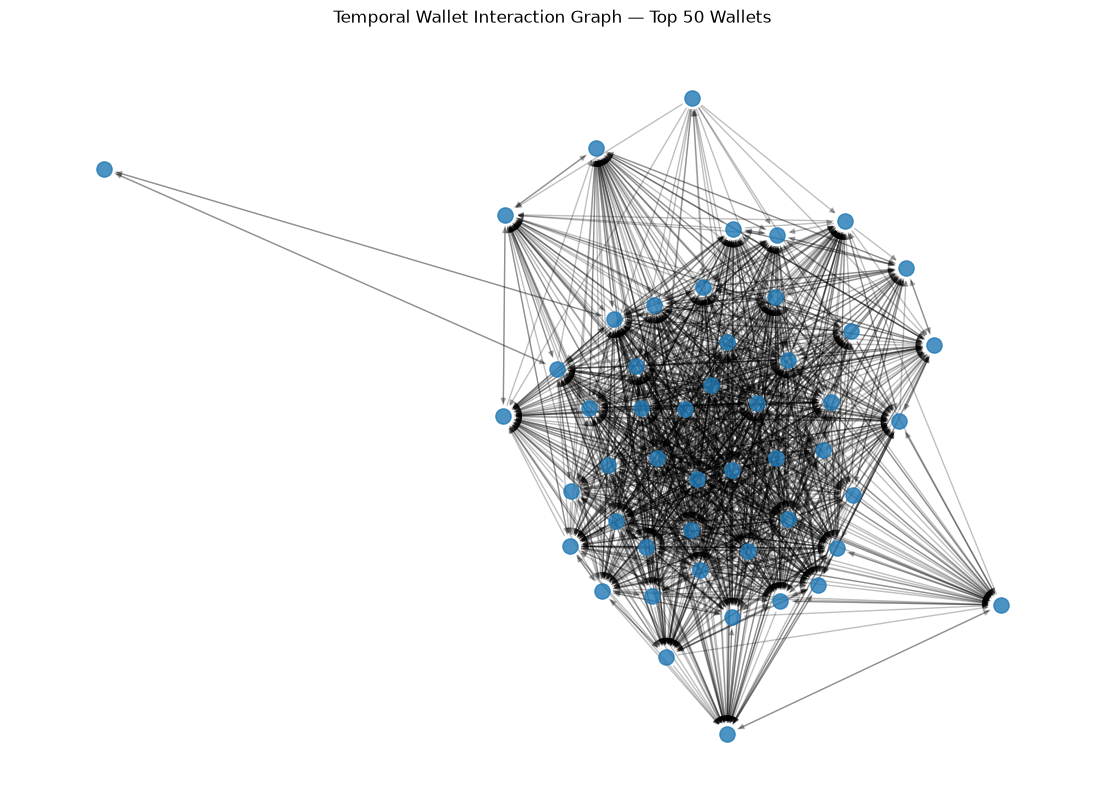

In [42]:
plt.figure(figsize=(14, 10))

pos = nx.spring_layout(
    G,
    seed=42,
    k=0.8
)

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=120,
    alpha=0.8
)

nx.draw_networkx_edges(
    G,
    pos,
    arrows=True,
    arrowsize=8,
    alpha=0.25
)

plt.title("Temporal Wallet Interaction Graph — Top 50 Wallets")
plt.axis("off")
plt.show()

In [43]:
import torch
from torch_geometric.data import Data

/Users/arulnanda/Desktop/polymap/.venv/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [44]:
data = Data(
    x=torch.tensor(
        X_scaled,
        dtype=torch.float32
    ),
    
    edge_index=torch.tensor(
        edge_index,
        dtype=torch.long
    ),
    
    edge_attr=torch.tensor(
        edge_attr,
        dtype=torch.float32
    )
)

data.timestamp = torch.tensor(
    timestamps,
    dtype=torch.long
)

print(data)

Data(x=[2356, 9], edge_index=[2, 103779], edge_attr=[103779, 4], timestamp=[103779])


In [45]:
print("Nodes:", data.num_nodes)
print("Edges:", data.num_edges)
print("Node features:", data.num_node_features)
print("Edge features:", data.edge_attr.shape[1])

Nodes: 2356
Edges: 103779
Node features: 9
Edge features: 4


In [46]:
import sys

sys.path.append("../src")

from polymap.graph import build_graph

In [47]:
(
    data,
    wallet_to_id,
    id_to_wallet,
    node_features_graph,
    scaler,
) = build_graph(
    temporal_edges,
    wallet_features,
)

In [48]:
print(data)
print()
print("Nodes:", data.num_nodes)
print("Edges:", data.num_edges)
print("Node features:", data.num_node_features)
print("Edge features:", data.edge_attr.shape[1])

Data(x=[2356, 9], edge_index=[2, 103779], edge_attr=[103779, 4], timestamp=[103779])

Nodes: 2356
Edges: 103779
Node features: 9
Edge features: 4


In [49]:
temporal_edges.to_parquet(
    "../data/processed/temporal_edges.parquet",
    index=False
)

wallet_features.to_parquet(
    "../data/processed/wallet_features.parquet",
    index=False
)